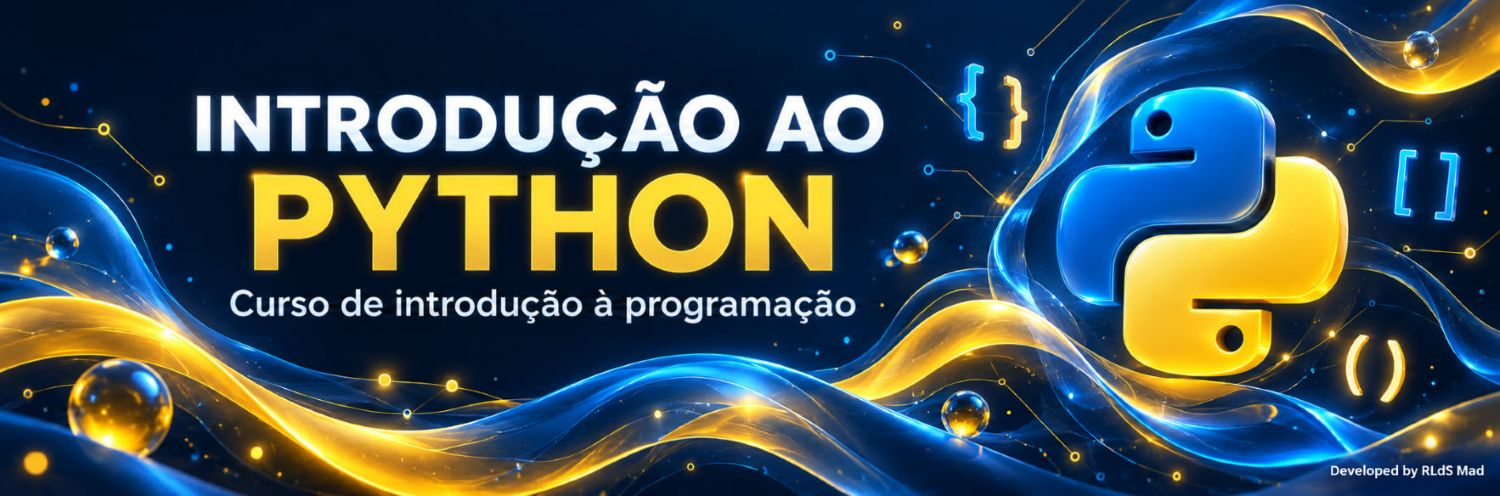

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_14_Modelos_Linguagem_BERT.ipynb)

# Nível IA · Módulo 14 – Modelos de linguagem pré-treinados
## BERT e afins: pré-treino, afinação e classificação de textos

O N3_07 terminou com uma ideia: em vez de treinar um modelo de texto de raiz, usar um ***transformer* pré-treinado**. O N3_12 mostrou o mecanismo de atenção que está por dentro. Este módulo junta as duas coisas e abre a caixa: como é que um modelo como o **BERT** aprende a língua **sem rótulos**, e como é que esse conhecimento se reaproveita para **classificar textos** com poucos exemplos.

O módulo tem duas partes. Na primeira (secções 1 e 2) constrói-se um **mini-BERT de raiz** em PyTorch, pré-treinado nas avaliações sintéticas do N3_07; corre no CPU, sem Internet, e mostra com números o que o pré-treino aprende **e o que não aprende**. Na segunda (secções 3 e 4) usam-se **modelos reais** em português, através da biblioteca `transformers`; esta parte precisa de Internet e corre bem no Colab.

> **Objetivos:** distinguir codificadores (BERT), descodificadores (GPT) e codificadores-descodificadores (T5); perceber o pré-treino por modelação de linguagem com máscara (MLM) e a regra 80/10/10; implementar e pré-treinar um mini-BERT; medir o que o pré-treino aprendeu (gramática sim, polaridade nem tanto) e porquê; comparar afinação com e sem pré-treino e com TF-IDF; usar modelos reais para tokenização em subpalavras, preenchimento de máscaras e *embeddings* contextuais; classificar textos de três formas (*pipeline*, extração de características, afinação completa); escolher entre um modelo pré-treinado e o TF-IDF.

**Pré-requisitos:** N3_05 (PyTorch), N3_07 (texto, TF-IDF e o corpus de avaliações) e N3_12 (atenção e codificação posicional).

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e vocabulário |
| 1. Do *transformer* ao BERT | arquiteturas, pré-treino e a família de modelos |
| 2. Um mini-BERT de raiz | pré-treino com máscara e afinação, sem Internet |
| 3. Modelos reais em português | subpalavras, máscaras e contexto (com Internet) |
| 4. Três formas de classificar textos | *pipeline*, características e afinação (com Internet) |
| 5. Boas práticas | variante da língua, limites, custos e alternativas |
| 6. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas

As secções 1 e 2 precisam só do PyTorch (instruções no N3_05, secção 0.1) e do scikit-learn. As secções 3 e 4 precisam também da biblioteca `transformers`, da Hugging Face, e de Internet para descarregar os modelos. No **Colab** está tudo instalado; no teu computador, `python -m pip install transformers`. Sem `transformers` ou sem Internet, as células dessas secções avisam e não fazem nada, e o resto do módulo funciona na mesma.

O pré-treino do mini-BERT (secção 2.4) e a comparação da secção 2.6 demoram cada um entre um e dois minutos no CPU (no Colab sem GPU, cerca de dois).

In [1]:
# Executar esta célula

import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

try:
    import torch
    from torch import nn
except ImportError:
    raise ImportError("O PyTorch não está instalado. Vê a secção 0.1 do N3_05.")

try:
    import transformers
    from transformers import (AutoModelForMaskedLM, AutoModelForSequenceClassification,
                              AutoTokenizer, pipeline)
    transformers.logging.set_verbosity_error()  # esconde avisos longos ao carregar modelos
    TEM_TRANSFORMERS = True
except ImportError:
    TEM_TRANSFORMERS = False

plt.rcParams.update({"figure.dpi": 100})
torch.manual_seed(0)
np.random.seed(0)
print(f"PyTorch {torch.__version__} | transformers: "
      f"{transformers.__version__ if TEM_TRANSFORMERS else 'não instalado (secções 3 e 4 ficam por executar)'}")

PyTorch 2.15.0+cu132 | transformers: 5.23.0


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Modelo pré-treinado** | um modelo treinado numa tarefa genérica com muito texto, para depois ser reaproveitado |
| **Pré-treino auto-supervisionado** | treino em que os rótulos saem do próprio texto (por exemplo, palavras escondidas), sem anotação humana |
| **MLM** (*masked language modeling*) | a tarefa de pré-treino do BERT: adivinhar palavras substituídas por `[MASK]` |
| **Afinação** (*fine-tuning*) | continuar o treino de um modelo pré-treinado numa tarefa concreta, com rótulos |
| **Extração de características** | usar o modelo pré-treinado congelado para obter vetores, e treinar só um classificador simples por cima |
| ***Token* especial** | símbolos como `[CLS]` (início), `[SEP]` (fim de frase), `[PAD]` (enchimento) e `[MASK]` |
| **Subpalavra** | pedaço de palavra; os modelos reais partem as palavras raras em subpalavras frequentes |
| ***Embedding* contextual** | o vetor de uma palavra calculado a partir da frase inteira, diferente de contexto para contexto |
| **Aprendizagem por transferência** | reaproveitar o que um modelo aprendeu numa tarefa para outra |

## 1. Do *transformer* ao BERT

### 1.1 Três formas de usar o *transformer*

O *transformer* original (Vaswani et al., 2017) tinha duas metades: um **codificador**, que lê a frase de entrada inteira, e um **descodificador**, que gera a frase de saída palavra a palavra. Os modelos que vieram depois ficaram, em geral, com uma das metades ou com as duas:

| Tipo | Atenção | Pré-treino típico | Exemplos | Bom para |
| --- | --- | --- | --- | --- |
| **Codificador** | cada palavra vê **todas** as outras (bidirecional) | adivinhar palavras escondidas (MLM) | BERT, RoBERTa, DeBERTa | classificar, extrair, comparar textos |
| **Descodificador** | cada palavra só vê as **anteriores** (causal) | prever a palavra seguinte | GPT, Llama, Claude | gerar texto, conversar |
| **Codificador-descodificador** | o codificador lê, o descodificador gera | reconstruir partes apagadas do texto | T5, BART | traduzir, resumir |

Este módulo trata dos **codificadores**. Como cada palavra vê a frase toda, o vetor de saída de cada posição resume o contexto completo, o que é exatamente o que se quer para **classificar** ou **comparar** textos. Os grandes modelos generativos também classificam (basta pedir-lhes), mas um codificador é centenas de vezes mais pequeno, mais rápido e pode ser afinado num portátil ou no Colab.

### 1.2 O pré-treino do BERT

O BERT (Devlin et al., 2019) aprende em duas fases. Na primeira, o **pré-treino**, lê enormes quantidades de texto sem rótulos. Escolhe-se 15 % dos *tokens* de cada frase e pede-se ao modelo que os adivinhe a partir do resto: é a **modelação de linguagem com máscara** (MLM). Dos *tokens* escolhidos, 80 % são substituídos por `[MASK]`, 10 % por um *token* ao acaso e 10 % ficam iguais. Assim o modelo não pode confiar em que só as posições com `[MASK]` importam, porque na afinação nunca vai ver `[MASK]`.

A perda é a entropia cruzada, calculada **só nas posições escolhidas** $M$:

$$\mathcal{L}_{\text{MLM}} = -\frac{1}{|M|} \sum_{i \in M} \log p_\theta(x_i \mid \tilde{x})$$

em que $\tilde{x}$ é a frase com as substituições. Os rótulos saem do próprio texto, por isso o pré-treino pode usar todo o texto que houver: o BERT original usou a Wikipédia inglesa e uma coleção de livros, cerca de 3300 milhões de palavras.

Na segunda fase, a **afinação**, junta-se uma camada pequena por cima (por exemplo, uma regressão logística sobre o vetor do *token* `[CLS]`) e treina-se tudo com os exemplos rotulados da tarefa. Como o modelo já «sabe» a língua, bastam muito menos exemplos do que treinar de raiz.

O BERT original tinha uma segunda tarefa de pré-treino, prever se duas frases eram seguidas no texto (*next sentence prediction*). Os modelos seguintes deixaram-na cair, por ajudar pouco.

### 1.3 A família

| Modelo | Ano | Ideia principal |
| --- | --- | --- |
| **BERT** | 2018 | codificador pré-treinado com MLM; versão *base* com 12 camadas e cerca de 110 milhões de parâmetros |
| **RoBERTa** | 2019 | o mesmo modelo, treinado mais tempo, com mais dados, sem a segunda tarefa e com máscaras novas a cada época |
| **DistilBERT** | 2019 | um BERT mais pequeno, treinado a imitar o grande (destilação); mais rápido, com perda pequena de qualidade |
| **XLM-RoBERTa** | 2019 | RoBERTa treinado em cerca de 100 línguas, incluindo o português |
| **DeBERTa** | 2020 | separa o conteúdo e a posição de cada palavra no cálculo da atenção |

Para português há modelos treinados especificamente na língua, que em geral funcionam melhor do que os multilingues:

- **BERTimbau** (Souza et al., 2020), treinado em texto do **português do Brasil**; no Hugging Face, `neuralmind/bert-base-portuguese-cased`.
- **Albertina** (Rodrigues et al., 2023), da Universidade de Lisboa, baseado no DeBERTa, com versões para **português europeu** (PT-PT) e do Brasil; usamos a versão PT-PT mais pequena (Santos et al., 2024), com cerca de 100 milhões de parâmetros: `PORTULAN/albertina-100m-portuguese-ptpt-encoder`.

Os números exatos (camadas, parâmetros, dados de treino, licença) estão na página de cada modelo no Hugging Face (o *model card*), que vale a pena ler antes de usar qualquer modelo.

## 2. Um mini-BERT de raiz

Para perceber o que o pré-treino faz, o melhor é fazê-lo. Esta secção constrói um BERT minúsculo (cerca de cem mil parâmetros, contra os 110 milhões do original), pré-treina-o em avaliações **sem rótulo** e depois afina-o para classificar o sentimento com **poucos** exemplos rotulados. A pergunta é a mesma que motiva os modelos reais: **o pré-treino ajuda quando há poucos rótulos?**

### 2.1 Os dados

Usamos o gerador de avaliações do N3_07, agora como função: dá avaliações de uma loja, com aspetos («a entrega», «o preço»), adjetivos com género, negações, frases feitas e algumas avaliações mistas («..., mas ...»). O rótulo é 1 se a maioria das partes for positiva, com 4 % de rótulos trocados de propósito, como nos dados reais. Geramos três conjuntos independentes:

- 20 000 avaliações **sem rótulo**, para o pré-treino (na prática, o texto sem anotação é barato e abundante);
- 2000 avaliações **rotuladas**, das quais usamos só uma parte em cada experiência;
- 1000 avaliações de **teste**.

In [2]:
# Executar esta célula

ASPETOS = {"o produto": "m", "a entrega": "f", "a qualidade": "f", "o preço": "m", "o atendimento": "m",
           "a embalagem": "f", "o tamanho": "m", "a aplicação": "f", "o material": "m", "a loja": "f"}
POS = {"m": ["bom", "ótimo", "excelente", "fantástico", "impecável", "perfeito"],
       "f": ["boa", "ótima", "excelente", "fantástica", "impecável", "perfeita"]}
NEG = {"m": ["mau", "péssimo", "horrível", "fraco", "terrível", "dececionante"],
       "f": ["má", "péssima", "horrível", "fraca", "terrível", "dececionante"]}
INTENS = ["", "", "muito ", "bastante ", "mesmo "]
FRASES_POS = ["adorei", "recomendo", "voltarei a comprar", "chegou rápido", "superou as expectativas",
              "vale cada cêntimo", "estou muito satisfeito", "cinco estrelas", "tudo correu bem"]
FRASES_NEG = ["não recomendo", "nunca mais compro", "chegou atrasado", "veio partido", "uma desilusão",
              "estou arrependido", "dinheiro mal gasto", "pedi reembolso", "foi uma perda de tempo"]
NEUTRAS = ["comprei para oferecer", "encomendei na semana passada", "é a segunda vez que compro",
           "usei durante um mês", "comprei na promoção", "vi a publicidade na internet"]


def gerar_avaliacoes(n, semente):
    """Devolve n avaliações sintéticas e os rótulos (1 = positiva)."""
    rng = np.random.default_rng(semente)

    def frase_aspeto(polaridade):
        aspeto, genero = list(ASPETOS.items())[rng.integers(len(ASPETOS))]
        verbo = rng.choice(["é", "está", "foi"])
        if rng.random() < 0.25:  # negação: «não é bom» é negativo
            return f"{aspeto} não {verbo} {rng.choice(POS[genero] if polaridade < 0 else NEG[genero])}"
        return f"{aspeto} {verbo} {rng.choice(INTENS)}{rng.choice(POS[genero] if polaridade > 0 else NEG[genero])}"

    textos, rotulos = [], []
    for _ in range(n):
        sentimento = 1 if rng.random() < 0.5 else -1
        partes, total = [], 0
        if rng.random() < 0.4:
            partes.append(str(rng.choice(NEUTRAS)))
        for _ in range(rng.integers(1, 4)):
            polaridade = sentimento if rng.random() < 0.8 else -sentimento
            partes.append(frase_aspeto(polaridade) if rng.random() < 0.55
                          else str(rng.choice(FRASES_POS if polaridade > 0 else FRASES_NEG)))
            total += polaridade
        if total == 0:
            total = sentimento
        texto = partes[0]
        for parte in partes[1:]:
            texto += rng.choice([", ", ". ", " e ", ", mas "]) + parte
        textos.append(texto[0].upper() + texto[1:] + rng.choice([".", "!", ".", "..."]))
        rotulo = int(total > 0)
        if rng.random() < 0.04:  # ruído nos rótulos
            rotulo = 1 - rotulo
        rotulos.append(rotulo)
    return textos, np.array(rotulos)


sem_rotulo, _ = gerar_avaliacoes(20000, semente=1)  # os rótulos deste conjunto não são usados
treino_txt, treino_y = gerar_avaliacoes(2000, semente=2)
teste_txt, teste_y = gerar_avaliacoes(1000, semente=3)
for t, y in zip(treino_txt[:5], treino_y[:5]):
    print(y, t)
print(f"\nPositivas no teste: {teste_y.mean():.1%}")

1 É a segunda vez que compro e cinco estrelas, mas a aplicação está ótima, mas a embalagem foi bastante ótima...
1 Comprei na promoção. uma desilusão e voltarei a comprar.
1 É a segunda vez que compro, vale cada cêntimo, mas o tamanho foi muito ótimo. veio partido!
1 A qualidade está bastante ótima...
1 A embalagem não está péssima. recomendo, recomendo!

Positivas no teste: 49.0%


### 2.2 *Tokens* e *tokens* especiais

Os modelos reais usam subpalavras (secção 3.1). O nosso vocabulário é tão pequeno que basta partir o texto em palavras e pontuação. Juntamos os cinco *tokens* especiais do BERT e convertemos cada avaliação numa sequência de números com o formato `[CLS] palavras ... [SEP] [PAD] [PAD] ...`, com 32 posições.

In [3]:
# Executar esta célula

ESPECIAIS = ["[PAD]", "[CLS]", "[SEP]", "[MASK]", "[UNK]"]
PAD, CLS, SEP, MASK, UNK = range(5)
COMPRIMENTO = 32


def tokenizar(texto):
    return re.findall(r"\w+|[^\w\s]", texto.lower())


contagem = Counter(tok for t in sem_rotulo for tok in tokenizar(t))
VOCAB = ESPECIAIS + sorted(contagem)
INDICE = {palavra: i for i, palavra in enumerate(VOCAB)}


def codificar(textos):
    ids = torch.full((len(textos), COMPRIMENTO), PAD, dtype=torch.long)
    for i, texto in enumerate(textos):
        toks = [CLS] + [INDICE.get(w, UNK) for w in tokenizar(texto)][:COMPRIMENTO - 2] + [SEP]
        ids[i, :len(toks)] = torch.tensor(toks)
    return ids


print("Tamanho do vocabulário:", len(VOCAB))
print("Avaliação mais longa:", max(len(tokenizar(t)) for t in sem_rotulo), "tokens")
exemplo = codificar([treino_txt[0]])[0]
print(treino_txt[0])
print([VOCAB[i] for i in exemplo])

Tamanho do vocabulário: 102
Avaliação mais longa: 29 tokens


É a segunda vez que compro e cinco estrelas, mas a aplicação está ótima, mas a embalagem foi bastante ótima...
['[CLS]', 'é', 'a', 'segunda', 'vez', 'que', 'compro', 'e', 'cinco', 'estrelas', ',', 'mas', 'a', 'aplicação', 'está', 'ótima', ',', 'mas', 'a', 'embalagem', 'foi', 'bastante', 'ótima', '.', '.', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


### 2.3 O modelo

O mini-BERT é um codificador *transformer* como o do N3_12, agora com as peças do PyTorch: um *embedding* por *token*, um *embedding* aprendido por posição, e duas camadas `nn.TransformerEncoderLayer` com 4 cabeças de atenção e vetores de dimensão 64. A máscara `src_key_padding_mask` diz à atenção para ignorar as posições `[PAD]`. A camada `mlm` transforma o vetor de cada posição numa pontuação para cada palavra do vocabulário e só se usa no pré-treino.

In [4]:
# Executar esta célula

class MiniBERT(nn.Module):
    def __init__(self, vocabulario, d=64, camadas=2, cabecas=4):
        super().__init__()
        self.tokens = nn.Embedding(vocabulario, d)
        self.posicoes = nn.Embedding(COMPRIMENTO, d)
        self.norma = nn.LayerNorm(d)
        bloco = nn.TransformerEncoderLayer(d, cabecas, dim_feedforward=4 * d, dropout=0.1,
                                           activation="gelu", batch_first=True)
        self.codificador = nn.TransformerEncoder(bloco, camadas, enable_nested_tensor=False)
        self.mlm = nn.Linear(d, vocabulario)

    def forward(self, ids):
        """Devolve um vetor de dimensão d por posição: (lote, COMPRIMENTO, d)."""
        x = self.norma(self.tokens(ids) + self.posicoes(torch.arange(ids.shape[1])))
        return self.codificador(x, src_key_padding_mask=(ids == PAD))


torch.manual_seed(0)
print(f"Parâmetros do mini-BERT: {sum(p.numel() for p in MiniBERT(len(VOCAB)).parameters()):,}")

Parâmetros do mini-BERT: 115,302


### 2.4 Pré-treino com máscara

A função `mascarar` aplica a regra do BERT: escolhe 15 % das palavras (nunca os *tokens* especiais), põe `[MASK]` em 80 % delas, uma palavra ao acaso em 10 % e deixa as restantes. Os alvos das posições não escolhidas valem −100, o valor que `cross_entropy` ignora; assim a perda só conta as posições escolhidas, como na fórmula da secção 1.2.

Cada passo usa 64 avaliações sem rótulo e máscaras novas, por isso o modelo nunca vê o mesmo exercício duas vezes. São 1500 passos, com o otimizador AdamW.

Pré-treino: 62 s
Perda MLM média nos primeiros 50 passos: 3.98 | nos últimos 50: 0.85 | ao acaso seria ln(102) = 4.62


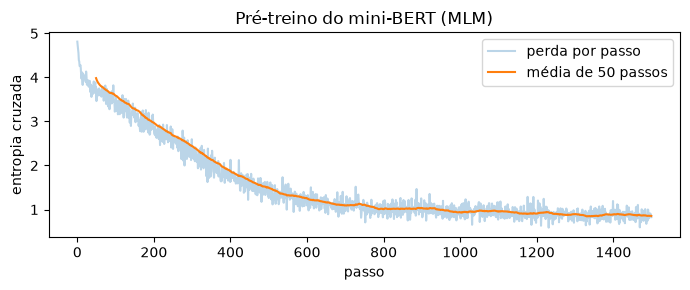

In [5]:
# Executar esta célula

def mascarar(ids, gerador, taxa=0.15):
    entrada, alvo = ids.clone(), ids.clone()
    escolhidos = (torch.rand(ids.shape, generator=gerador) < taxa) & (ids > UNK)  # só palavras
    alvo[~escolhidos] = -100
    sorteio = torch.rand(ids.shape, generator=gerador)
    entrada[escolhidos & (sorteio < 0.8)] = MASK                         # 80 %: [MASK]
    trocar = escolhidos & (sorteio >= 0.8) & (sorteio < 0.9)              # 10 %: palavra ao acaso
    entrada[trocar] = torch.randint(len(ESPECIAIS), len(VOCAB), (int(trocar.sum()),), generator=gerador)
    return entrada, alvo                                                  # 10 %: ficam iguais


def pretreinar(modelo, passos=1500, lote=64, semente=0):
    torch.manual_seed(semente)
    gerador = torch.Generator().manual_seed(semente)
    X = codificar(sem_rotulo)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3)
    historico = []
    for passo in range(passos):
        entrada, alvo = mascarar(X[torch.randint(0, len(X), (lote,), generator=gerador)], gerador)
        pontuacoes = modelo.mlm(modelo(entrada))                          # (lote, COMPRIMENTO, vocabulário)
        perda = nn.functional.cross_entropy(pontuacoes.transpose(1, 2), alvo, ignore_index=-100)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())
    return historico


inicio = time.time()
torch.manual_seed(0)
bert = MiniBERT(len(VOCAB))
historico = pretreinar(bert)
bert.eval()
print(f"Pré-treino: {time.time() - inicio:.0f} s")
media_movel = pd.Series(historico).rolling(50).mean()
print(f"Perda MLM média nos primeiros 50 passos: {np.mean(historico[:50]):.2f} | "
      f"nos últimos 50: {np.mean(historico[-50:]):.2f} | ao acaso seria ln({len(VOCAB)}) = {np.log(len(VOCAB)):.2f}")

plt.figure(figsize=(7, 3))
plt.plot(historico, alpha=0.3, label="perda por passo")
plt.plot(media_movel, label="média de 50 passos")
plt.xlabel("passo")
plt.ylabel("entropia cruzada")
plt.title("Pré-treino do mini-BERT (MLM)")
plt.legend()
plt.tight_layout()
plt.show()

### 2.5 O que é que o pré-treino aprendeu?

A perda desceu muito, mas isso só diz que o modelo adivinha melhor as palavras escondidas. Para saber **o quê**, fazemos-lhe perguntas. A função `preencher` mostra as palavras mais prováveis para um `[MASK]`. Depois medimos duas coisas em todos os aspetos:

- **Concordância de género:** em «a entrega é [MASK].», que fração da probabilidade dada a adjetivos com género vai para a forma feminina?
- **Polaridade:** em «adorei, a entrega é [MASK] e recomendo.», que fração da probabilidade dada a adjetivos vai para os positivos? E com um contexto negativo à volta?

In [6]:
# Executar esta célula

def probabilidades_mascara(modelo, frase):
    ids = codificar([frase.replace("[MASK]", "qqqq")])  # «qqqq» não está no vocabulário: fica [UNK]
    posicao = (ids[0] == UNK).nonzero()[0, 0]
    ids[0, posicao] = MASK
    with torch.no_grad():
        return modelo.mlm(modelo(ids))[0, posicao].softmax(-1)


def preencher(modelo, frase, k=5):
    p = probabilidades_mascara(modelo, frase)
    melhores = p.topk(k)
    return [(VOCAB[int(i)], round(float(v), 2)) for v, i in zip(melhores.values, melhores.indices)]


for frase in ["a entrega é [MASK].", "o preço é [MASK].", "adorei, o produto é [MASK] e recomendo.",
              "[MASK] a comprar."]:
    print(f"{frase:42s}", preencher(bert, frase))

a entrega é [MASK].                        [('má', 0.13), ('fraca', 0.13), ('perfeita', 0.1), ('horrível', 0.1), ('terrível', 0.09)]
o preço é [MASK].                          [('mau', 0.11), ('fantástico', 0.1), ('péssimo', 0.1), ('terrível', 0.1), ('bom', 0.09)]
adorei, o produto é [MASK] e recomendo.    [('terrível', 0.14), ('excelente', 0.11), ('horrível', 0.1), ('dececionante', 0.09), ('perfeito', 0.09)]
[MASK] a comprar.                          [('voltarei', 0.99), ('é', 0.0), ('comprei', 0.0), ('estou', 0.0), ('comprar', 0.0)]


In [7]:
# Executar esta célula

def massa(p, palavras):
    return float(sum(p[INDICE[w]] for w in set(palavras)))


def avaliar_conhecimento(modelo):
    so_m = [w for w in POS["m"] + NEG["m"] if w not in POS["f"] + NEG["f"]]  # adjetivos com género marcado
    so_f = [w for w in POS["f"] + NEG["f"] if w not in POS["m"] + NEG["m"]]
    genero, pol_pos, pol_neg = [], [], []
    todos_pos = POS["m"] + POS["f"]
    todos_adj = todos_pos + NEG["m"] + NEG["f"]
    for aspeto, g in ASPETOS.items():
        p = probabilidades_mascara(modelo, f"{aspeto} é [MASK].")
        certo, errado = (so_f, so_m) if g == "f" else (so_m, so_f)
        genero.append(massa(p, certo) / (massa(p, certo) + massa(p, errado)))
        p = probabilidades_mascara(modelo, f"adorei, {aspeto} é [MASK] e recomendo.")
        pol_pos.append(massa(p, todos_pos) / massa(p, todos_adj))
        p = probabilidades_mascara(modelo, f"não recomendo, {aspeto} é [MASK] e pedi reembolso.")
        pol_neg.append(massa(p, todos_pos) / massa(p, todos_adj))
    return {"género certo": np.mean(genero),
            "positivos | contexto positivo": np.mean(pol_pos),
            "positivos | contexto negativo": np.mean(pol_neg)}


torch.manual_seed(0)
conhecimento = pd.DataFrame({"sem pré-treino": avaliar_conhecimento(MiniBERT(len(VOCAB)).eval()),
                             "pré-treinado": avaliar_conhecimento(bert)})
print(conhecimento.round(2))

                               sem pré-treino  pré-treinado
género certo                             0.50          0.94
positivos | contexto positivo            0.42          0.42
positivos | contexto negativo            0.32          0.45


O pré-treino aprendeu a **gramática**. Com o modelo pré-treinado, 94 % da probabilidade dada a adjetivos com género marcado vai para o género certo, contra 50 % (o acaso) sem pré-treino. Também aprendeu as combinações fixas: em «[MASK] a comprar.», dá «voltarei» com probabilidade 0,99.

Mas **não aprendeu a polaridade**. A fração de adjetivos positivos é 0,42 num contexto positivo e 0,45 num contexto negativo, sem diferença útil; em «adorei, o produto é [MASK] e recomendo.», o adjetivo mais provável é «terrível».

Porquê? «Bom» e «mau» aparecem exatamente nos mesmos lugares («o produto é ___»), por isso o contexto próximo não os distingue. A única pista está nas **outras partes** da avaliação, e é fraca: o gerador mantém o sentimento de cada parte com probabilidade 0,8, logo duas partes concordam só com probabilidade $0{,}8^2 + 0{,}2^2 = 0{,}68$, e muitas vezes uma delas está negada. A concordância de género, pelo contrário, é uma pista forte e está sempre ao lado. O mesmo fenómeno aparece em modelos reais: os antónimos costumam ter vetores próximos, porque ocorrem nos mesmos contextos.

### 2.6 Afinação com poucos rótulos

Agora a tarefa a sério: classificar o sentimento. Juntamos ao codificador uma camada linear com duas saídas. Como representação da avaliação usamos a **média dos vetores** de todas as posições que não são `[PAD]`. O BERT real usa o vetor do `[CLS]`, mas no nosso pré-treino o `[CLS]` nunca foi alvo de nada, por isso usamos a média.

Comparamos três modelos com o **mesmo** número $n$ de avaliações rotuladas:

- **pré-treinado:** uma cópia do mini-BERT da secção 2.4, afinado (o codificador com taxa de aprendizagem baixa, para não destruir o que aprendeu; a camada nova com taxa maior);
- **de raiz:** a mesma arquitetura, com pesos aleatórios, treinada só com os $n$ exemplos;
- **TF-IDF:** a melhor combinação do N3_07, TF-IDF com trigramas e regressão logística.

Com tão poucos exemplos, o resultado depende muito de **quais** são escolhidos. Por isso cada valor é a média de três sorteios diferentes dos $n$ exemplos.

Exatidão no teste (média de 3 sorteios) | 43 s
     pré-treinado  de raiz  TF-IDF
n                                 
20          0.537    0.529   0.526
100         0.635    0.613   0.675
500         0.724    0.744   0.804

Desvio-padrão entre os 3 sorteios
     pré-treinado  de raiz  TF-IDF
n                                 
20          0.038    0.041   0.016
100         0.031    0.041   0.021
500         0.015    0.014   0.008


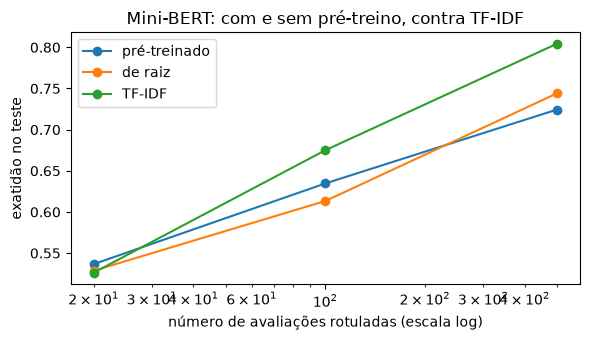

In [8]:
# Executar esta célula

import copy


def representacao(modelo, ids):
    """Média dos vetores das posições que não são [PAD]."""
    h = modelo(ids)
    mascara = (ids != PAD).unsqueeze(-1).float()
    return (h * mascara).sum(1) / mascara.sum(1)


class Classificador(nn.Module):
    def __init__(self, codificador):
        super().__init__()
        self.bert = codificador
        self.cabeca = nn.Linear(codificador.tokens.embedding_dim, 2)

    def forward(self, ids):
        return self.cabeca(representacao(self.bert, ids))


X_teste = codificar(teste_txt)


def afinar(codificador, indices, epocas, lr_codificador, semente=0):
    torch.manual_seed(semente)
    modelo = Classificador(codificador)
    X, y = codificar([treino_txt[i] for i in indices]), torch.tensor(treino_y[indices])
    otimizador = torch.optim.AdamW([{"params": modelo.bert.parameters(), "lr": lr_codificador},
                                    {"params": modelo.cabeca.parameters(), "lr": 1e-3}])
    for epoca in range(epocas):
        modelo.train()
        ordem = torch.randperm(len(indices))
        for i in range(0, len(indices), 16):
            lote = ordem[i:i + 16]
            otimizador.zero_grad()
            nn.functional.cross_entropy(modelo(X[lote]), y[lote]).backward()
            otimizador.step()
    modelo.eval()
    with torch.no_grad():
        return float((modelo(X_teste).argmax(1).numpy() == teste_y).mean())


def tfidf(indices):
    m = make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=(1, 3)), LogisticRegression(C=10, max_iter=2000))
    return m.fit([treino_txt[i] for i in indices], treino_y[indices]).score(teste_txt, teste_y)


inicio = time.time()
linhas = []
for n in (20, 100, 500):
    epocas = {20: 60, 100: 20, 500: 10}[n]  # aproximadamente o mesmo número de passos de treino
    for sorteio in range(3):
        indices = np.random.default_rng(sorteio).choice(len(treino_txt), n, replace=False)
        torch.manual_seed(sorteio)
        linhas.append({"n": n, "sorteio": sorteio,
                       "pré-treinado": afinar(copy.deepcopy(bert), indices, epocas, 2e-4, sorteio),
                       "de raiz": afinar(MiniBERT(len(VOCAB)), indices, epocas, 1e-3, sorteio),
                       "TF-IDF": tfidf(indices)})
resultados = pd.DataFrame(linhas)
tabela = resultados.groupby("n")[["pré-treinado", "de raiz", "TF-IDF"]].mean()
print(f"Exatidão no teste (média de 3 sorteios) | {time.time() - inicio:.0f} s")
print(tabela.round(3))
print("\nDesvio-padrão entre os 3 sorteios")
print(resultados.groupby("n")[["pré-treinado", "de raiz", "TF-IDF"]].std().round(3))

tabela.plot(marker="o", figsize=(6, 3.5), logx=True)
plt.xlabel("número de avaliações rotuladas (escala log)")
plt.ylabel("exatidão no teste")
plt.title("Mini-BERT: com e sem pré-treino, contra TF-IDF")
plt.tight_layout()
plt.show()

Com 20 exemplos, os três modelos ficam perto do acaso (entre 0,526 e 0,537): vinte avaliações não chegam, com ou sem pré-treino. Com 100, o mini-BERT pré-treinado fica ligeiramente à frente do treinado de raiz (0,635 contra 0,613), mas o TF-IDF ganha (0,675). Com 500, o pré-treinado fica até atrás do de raiz (0,724 contra 0,744), e o TF-IDF continua à frente (0,804). Os desvios-padrão mostram que as diferenças entre os dois mini-BERT são da mesma ordem que a variação entre sorteios.

O resultado é coerente com a secção 2.5: o pré-treino ensinou ao mini-BERT o que não ajuda a classificar (o género) e não o que ajuda (a polaridade). Além disso, o corpus é fácil para o TF-IDF: com cerca de cem palavras, poucas centenas de exemplos já cobrem quase todo o vocabulário, e os trigramas captam as negações.

A lição não é que o pré-treino não sirva. É que o seu valor vem da **escala e da variedade** do texto. Os modelos reais leem milhares de milhões de palavras, em que as pistas fracas de polaridade se repetem vezes sem conta, e são usados em tarefas com vocabulário que os poucos exemplos rotulados não cobrem. Num corpus pequeno e repetitivo, como este, o TF-IDF chega. A secção 4 permite pôr à prova um modelo real nas mesmas avaliações.

## 3. Modelos reais em português

> **Esta secção e a seguinte precisam de Internet** e da biblioteca `transformers`. No Colab funcionam sem configuração; o primeiro modelo demora um ou dois minutos a descarregar. Sem Internet, as células avisam e não fazem nada. Os números citados no texto vêm de uma **execução de referência** no Colab, com GPU A100, PyTorch 2.14 e `transformers` 5.22. Noutra versão das bibliotecas, de um modelo ou noutro equipamento, podem variar ligeiramente.

Usamos o **Albertina PT-PT** de 100 milhões de parâmetros, o mais pequeno dos modelos para português europeu. Na execução de referência, a célula conta 139 milhões de parâmetros; 38,6 milhões são os *embeddings* dos 50 265 *tokens* do vocabulário, e sem eles ficam os 101 milhões que dão nome ao modelo. A função `carregar` devolve o *tokenizer* e o modelo, ou `(None, None)` se não for possível, e mostra a mensagem do erro.

Dois pormenores práticos:

- Os pesos do Albertina estão guardados em `bfloat16`, um formato de 16 bits que poupa espaço. As versões recentes de `transformers` carregam o modelo nesse formato, mas parte do cálculo de atenção do DeBERTa é feita em 32 bits, e as duas coisas não se misturam (o erro é `expected m1 and m2 to have the same dtype`). Por isso `carregar` converte o modelo para `float32` com `.float()`.
- O aviso «*You are sending unauthenticated requests to the HF Hub*» pode ser ignorado: os modelos usados são públicos. Uma chave gratuita do Hugging Face (`HF_TOKEN`, nos «Secrets» do Colab) só aumenta o limite de descargas.

In [9]:
# Executar esta célula

MODELO_PT = "PORTULAN/albertina-100m-portuguese-ptpt-encoder"


def carregar(nome, classe):
    """Devolve (tokenizer, modelo), ou (None, None) sem transformers ou sem Internet."""
    if not TEM_TRANSFORMERS:
        print("A biblioteca transformers não está instalada: esta célula não faz nada.")
        return None, None
    try:
        tok = AutoTokenizer.from_pretrained(nome)
        modelo = classe.from_pretrained(nome).float()  # os pesos podem vir em bfloat16: converter para float32
        return tok, modelo
    except Exception as erro:  # sem Internet, nome errado, limite de descargas, etc.
        print(f"Não foi possível carregar {nome} ({type(erro).__name__}: {str(erro)[:300]})")
        print("Esta célula não faz nada.")
        return None, None


tok_pt, mlm_pt = carregar(MODELO_PT, AutoModelForMaskedLM if TEM_TRANSFORMERS else None)
if mlm_pt is not None:
    mlm_pt.eval()
    total = sum(p.numel() for p in mlm_pt.parameters())
    vocabulario = mlm_pt.get_input_embeddings().weight.numel()  # um vetor por token do vocabulário
    print(f"{MODELO_PT}: {total / 1e6:.0f} milhões de parâmetros, dos quais {vocabulario / 1e6:.1f} milhões "
          f"nos embeddings de {tok_pt.vocab_size} tokens; sem eles, {(total - vocabulario) / 1e6:.0f} milhões")

PORTULAN/albertina-100m-portuguese-ptpt-encoder: 139 milhões de parâmetros, dos quais 38.6 milhões nos embeddings de 50265 tokens; sem eles, 101 milhões


### 3.1 Subpalavras

O vocabulário de um modelo real tem dezenas de milhares de *tokens*, mas não contém todas as palavras: as frequentes ficam inteiras e as raras partem-se em pedaços. Nunca há palavras desconhecidas, porque no limite qualquer palavra se escreve com pedaços pequenos. O limite de comprimento conta *tokens*, não palavras (num BERT é normalmente 512).

A forma de partir depende de **com que texto o vocabulário foi construído**. A célula seguinte compara o *tokenizer* do Albertina 100M com o do BERTimbau (só o *tokenizer*, que é pequeno). Os pedaços são mostrados já descodificados, entre barras, e um espaço no início de um pedaço indica o início de uma palavra no Albertina; no BERTimbau, `##` indica a continuação de uma palavra.

Repara em quais das palavras portuguesas mais comuns («foi», «entrega») ficam inteiras em cada um. O vocabulário do Albertina 100M tem 50 265 *tokens*, o mesmo tamanho e o mesmo estilo do do RoBERTa inglês, que o DeBERTa original, de onde o Albertina 100M parte, também usa; o do BERTimbau foi construído com texto em português. Um vocabulário que parte muito o português gasta mais *tokens* por frase e obriga o modelo a reconstruir as palavras a partir de pedaços.

In [10]:
# Executar esta célula

def pedacos(tok, frase):
    ids = tok(frase, add_special_tokens=False)["input_ids"]
    return [tok.decode([i]) for i in ids]


tok_bertimbau = None
if TEM_TRANSFORMERS:
    try:
        tok_bertimbau = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
    except Exception as erro:
        print(f"Não foi possível carregar o tokenizer do BERTimbau ({type(erro).__name__}).")

for nome, tok in [("Albertina 100M", tok_pt), ("BERTimbau", tok_bertimbau)]:
    if tok is None:
        continue
    print(f"--- {nome} (vocabulário de {tok.vocab_size} tokens)")
    for frase in ["A entrega foi impecável.", "O atendimento foi dececionante.",
                  "Inconstitucionalissimamente", "Comprei-o na promoção e veio partido."]:
        p = pedacos(tok, frase)
        print(f"{frase:40s} {len(p):2d} tokens: " + "|".join(p))

--- Albertina 100M (vocabulário de 50265 tokens)
A entrega foi impecável.                 11 tokens: A| ent|reg|a| fo|i| impe|c|á|vel|.
O atendimento foi dececionante.          12 tokens: O| at|end|iment|o| fo|i| dece|c|ion|ante|.
Inconstitucionalissimamente               9 tokens: In|const|it|uc|ional|iss|im|ament|e
Comprei-o na promoção e veio partido.    15 tokens: Comp|re|i|-|o| na| promo|ç|ão| e| ve|io| part|ido|.
--- BERTimbau (vocabulário de 29794 tokens)
A entrega foi impecável.                  7 tokens: A|entrega|foi|impe|##cá|##vel|.
O atendimento foi dececionante.           8 tokens: O|atendimento|foi|dec|##ec|##ion|##ante|.
Inconstitucionalissimamente               6 tokens: Inc|##ons|##titu|##cional|##iss|##imamente
Comprei-o na promoção e veio partido.    10 tokens: Comp|##rei|-|o|na|promoção|e|veio|partido|.


Na execução de referência, as quatro frases ocupam 47 *tokens* no Albertina 100M e 31 no BERTimbau. O Albertina parte até palavras muito frequentes: «foi» fica «fo|i» e «entrega» fica «ent|reg|a», e o «á» de «impecável» fica num *token* à parte. O BERTimbau mantém inteiras «entrega», «foi», «atendimento», «promoção» e «partido», e só parte as palavras raras. A diferença não impede o Albertina de funcionar (secção 4), mas cada frase gasta mais posições do limite de comprimento, e o modelo tem de juntar o sentido de pedaços que, sozinhos, não querem dizer nada.

### 3.2 Preencher a máscara

O modelo pré-treinado faz exatamente a tarefa do pré-treino: adivinhar o *token* escondido. Usamos `tok_pt.mask_token`, porque cada modelo tem o seu símbolo de máscara. Compara com o mini-BERT da secção 2.5: o modelo real aprendeu com muito texto em português, por isso pode «saber» geografia, gramática e associações de sentimento que o nosso nunca poderia aprender com cem palavras diferentes.

In [11]:
# Executar esta célula

def preencher_real(frase, k=5):
    entrada = tok_pt(frase.replace("[MASK]", tok_pt.mask_token), return_tensors="pt")
    posicao = (entrada["input_ids"][0] == tok_pt.mask_token_id).nonzero()[0, 0]
    with torch.no_grad():
        p = mlm_pt(**entrada).logits[0, posicao].softmax(-1)
    melhores = p.topk(k)
    return [(tok_pt.decode([int(i)]).strip(), round(float(v), 3)) for v, i in zip(melhores.values, melhores.indices)]


if mlm_pt is not None:
    for frase in ["Lisboa é a [MASK] de Portugal.", "A entrega é [MASK].",
                  "Adorei, o produto é [MASK] e recomendo.", "Não recomendo, o produto é [MASK]."]:
        print(f"{frase:42s}", preencher_real(frase))

Lisboa é a [MASK] de Portugal.             [('capital', 0.964), ('Capital', 0.035), ('Capital', 0.0), ('Europa', 0.0), ('sul', 0.0)]
A entrega é [MASK].                        [('individual', 0.228), ('manual', 0.196), ('online', 0.117), ('regular', 0.078), ('normal', 0.068)]
Adorei, o produto é [MASK] e recomendo.    [('bom', 0.862), ('natural', 0.035), ('original', 0.028), ('ideal', 0.02), ('super', 0.009)]
Não recomendo, o produto é [MASK].         [('original', 0.383), ('vulgar', 0.115), ('irregular', 0.061), ('inferior', 0.055), ('stock', 0.05)]


Na execução de referência:

- «Lisboa é a [MASK] de Portugal.» tem uma resposta clara: «capital», com probabilidade 0,964 (e «Capital», com maiúscula, 0,035). É conhecimento do mundo, aprendido só a ler.
- Em «A entrega é [MASK].», as cinco sugestões («individual», «manual», «online», «regular», «normal») são adjetivos que servem para os dois géneros, por isso não há erro de concordância. Mas nenhuma é uma avaliação: sem mais contexto, uma «entrega» pode ser de muita coisa.
- Num contexto positivo («Adorei, ... e recomendo.»), o modelo sugere «bom» com 0,862. Num contexto negativo («Não recomendo, ...»), a primeira sugestão é «original» (0,383), seguida de «vulgar», «irregular» e «inferior». O contexto muda as sugestões, coisa que o mini-BERT não conseguiu (secção 2.5), mas a tarefa do pré-treino só pede palavras **plausíveis**, não palavras com a polaridade certa. É a afinação que vai transformar este conhecimento num classificador.

### 3.3 *Embeddings* contextuais

No N3_07, cada palavra tinha **um** vetor, fosse qual fosse a frase. Num codificador como o BERT, o vetor de cada palavra é calculado a partir da frase inteira. A palavra «banco» tem dois sentidos; se os vetores forem mesmo contextuais, os dois usos financeiros devem parecer-se mais um com o outro do que com os usos de mobiliário. Calculamos o vetor de «banco» em quatro frases (a média dos *tokens* em que a palavra foi partida, se for o caso) e a semelhança de cosseno entre eles.

In [12]:
# Executar esta célula

def vetor_palavra(frase, palavra, tok, modelo):
    entrada = tok(frase, return_tensors="pt", return_offsets_mapping=True)
    desvios = entrada.pop("offset_mapping")[0].tolist()
    ini = frase.index(palavra)
    fim = ini + len(palavra)
    posicoes = [i for i, (a, b) in enumerate(desvios) if a < fim and b > ini and b > a]  # tokens da palavra
    with torch.no_grad():
        return modelo(**entrada).last_hidden_state[0, posicoes].mean(0)


if mlm_pt is not None:
    frases = ["Fui ao banco levantar dinheiro.", "O banco aprovou o empréstimo.",
              "Sentei-me no banco do jardim.", "O banco de madeira do parque estava partido."]
    V = torch.stack([vetor_palavra(f, "banco", tok_pt, mlm_pt.base_model) for f in frases])
    V = nn.functional.normalize(V, dim=1)
    print(pd.DataFrame((V @ V.T).numpy(), index=frases, columns=["fin. 1", "fin. 2", "jardim", "parque"]).round(2))

                                              fin. 1  fin. 2  jardim  parque
Fui ao banco levantar dinheiro.                 1.00    0.92    0.87    0.88
O banco aprovou o empréstimo.                   0.92    1.00    0.82    0.86
Sentei-me no banco do jardim.                   0.87    0.82    1.00    0.95
O banco de madeira do parque estava partido.    0.88    0.86    0.95    1.00


Com *embeddings* estáticos como os do N3_07, as quatro semelhanças seriam todas iguais a 1. Na execução de referência, as duas frases financeiras têm semelhança 0,92 entre si e as duas de mobiliário 0,95, enquanto os pares com sentidos diferentes ficam entre 0,82 e 0,88: os usos com o mesmo sentido são os mais parecidos. Repara, ainda assim, que todos os valores passam de 0,8. O vetor de «banco» guarda muito do que a palavra é, e o contexto só o desloca; além disso, os vetores dos modelos do tipo BERT tendem a ocupar uma região estreita do espaço. Ao comparar vetores contextuais, conta a diferença relativa, não o valor absoluto.

## 4. Três formas de classificar textos

Há três maneiras de pôr um modelo pré-treinado a classificar, por ordem crescente de esforço e, em geral, de qualidade. Usamos as avaliações da secção 2, com as **primeiras 200** rotuladas para treino e o mesmo conjunto de teste, e comparamos no fim com o TF-IDF e o mini-BERT.

### 4.1 *Pipeline* pronto, sem treino

O caminho mais curto é um modelo que já foi afinado para sentimento por outra pessoa, como no N3_07. Não usa nenhum dos nossos rótulos. O modelo dá três classes (positivo, neutro, negativo); contamos como positiva uma avaliação em que «positive» tenha mais probabilidade do que «negative».

In [13]:
# Executar esta célula

MODELO_SENTIMENTO = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
comparacao = {"TF-IDF (n=200)": tfidf(np.arange(200))}

classificar = None
if TEM_TRANSFORMERS:
    try:
        classificar = pipeline("text-classification", model=MODELO_SENTIMENTO, device=DISPOSITIVO)
    except Exception as erro:
        print(f"Não foi possível carregar {MODELO_SENTIMENTO} ({type(erro).__name__}: {str(erro)[:300]})")
        print("Esta célula não faz nada.")
else:
    print("A biblioteca transformers não está instalada: esta célula não faz nada.")

if classificar is not None:
    inicio = time.time()
    saidas = classificar(teste_txt, top_k=None, truncation=True, batch_size=32)
    pontos = [{s["label"]: s["score"] for s in saida} for saida in saidas]
    previsto = np.array([int(p.get("positive", 0) > p.get("negative", 0)) for p in pontos])
    comparacao["pipeline, sem treino"] = float((previsto == teste_y).mean())
    print(f"Pipeline sem treino: {comparacao['pipeline, sem treino']:.3f} | {time.time() - inicio:.0f} s")

Pipeline sem treino: 0.755 | 2 s


### 4.2 Extração de características

Usamos o codificador pré-treinado **congelado**, só para transformar cada avaliação num vetor (a média dos vetores dos *tokens*, como no mini-BERT), e treinamos por cima uma regressão logística do scikit-learn. É rápido, porque o modelo grande corre uma única vez por texto e não se calcula nenhum gradiente, e funciona razoavelmente com poucos exemplos.

In [14]:
# Executar esta célula

# Reaproveita o modelo da secção 3: o codificador é o modelo MLM sem a camada de saída
tok_enc, codificador_pt = (tok_pt, mlm_pt.base_model) if mlm_pt is not None else (None, None)
if codificador_pt is None:
    print("O modelo da secção 3 não foi carregado: esta célula não faz nada.")


def incorporar(textos, tok, modelo, lote=32):
    modelo.eval().to(DISPOSITIVO)
    vetores = []
    with torch.no_grad():
        for i in range(0, len(textos), lote):
            e = tok(textos[i:i + lote], padding=True, truncation=True, max_length=128,
                    return_tensors="pt").to(DISPOSITIVO)
            h = modelo(**e).last_hidden_state
            m = e["attention_mask"].unsqueeze(-1).float()  # ignora o enchimento na média
            vetores.append(((h * m).sum(1) / m.sum(1)).cpu())
    return torch.cat(vetores).numpy()


if codificador_pt is not None:
    inicio = time.time()
    F_treino = incorporar(treino_txt[:200], tok_enc, codificador_pt)
    F_teste = incorporar(teste_txt, tok_enc, codificador_pt)
    sonda = LogisticRegression(max_iter=5000).fit(F_treino, treino_y[:200])
    comparacao["características + reg. logística (n=200)"] = sonda.score(F_teste, teste_y)
    print(f"Características + regressão logística: {sonda.score(F_teste, teste_y):.3f} | {time.time() - inicio:.0f} s")

Características + regressão logística: 0.841 | 2 s


### 4.3 Afinação completa

Por fim, afinamos o modelo inteiro. `AutoModelForSequenceClassification` junta ao codificador uma camada de classificação nova (o aviso de que alguns pesos foram «inicializados de novo» refere-se a ela) e devolve a perda quando lhe passamos os rótulos. O ciclo de treino é o do N3_05, com três cuidados habituais na afinação de modelos grandes:

- uma **taxa de aprendizagem baixa** (3 × 10⁻⁵, muito menor do que no mini-BERT), para não destruir o que o pré-treino aprendeu;
- um **aquecimento** (*warm-up*): a taxa começa em zero e sobe durante os primeiros 10 % dos passos, depois desce linearmente até zero; no início, a camada nova é aleatória e os seus gradientes grandes podem desestabilizar o resto do modelo;
- **limitar a norma do gradiente** a 1, pela mesma razão.

Com só 200 exemplos, cada época tem 13 passos, por isso fazemos 10 épocas. Sem estes cuidados e com poucas épocas, é comum o modelo acabar a prever **a mesma classe para todos os textos**. A exatidão fica então igual à fração dessa classe no teste (0,49 ou 0,51), e é por isso que a célula mostra também quantas previsões há de cada classe.

Num GPU (no Colab: *Ambiente de execução* → *Alterar tipo de ambiente de execução* → GPU) demora menos de um minuto; no CPU, pode passar dos 20 minutos.

In [15]:
# Executar esta célula

def afinar_real(tok, modelo, textos, y, epocas=10, lote=16, lr=3e-5, aquecimento=0.1):
    modelo.to(DISPOSITIVO).train()
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    total = epocas * ((len(textos) + lote - 1) // lote)
    subida = max(1, int(aquecimento * total))
    # fator da taxa: sobe de 0 a 1 nos primeiros passos, depois desce até 0
    agenda = torch.optim.lr_scheduler.LambdaLR(
        otimizador, lambda passo: min((passo + 1) / subida, max(0.0, (total - passo) / (total - subida))))
    y = torch.tensor(y)
    for epoca in range(epocas):
        ordem = torch.randperm(len(textos))
        for i in range(0, len(textos), lote):
            indices = ordem[i:i + lote]
            e = tok([textos[j] for j in indices], padding=True, truncation=True, max_length=128,
                    return_tensors="pt").to(DISPOSITIVO)
            perda = modelo(**e, labels=y[indices].to(DISPOSITIVO)).loss
            otimizador.zero_grad()
            perda.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            otimizador.step()
            agenda.step()
        print(f"época {epoca + 1:2d}: perda do último lote {perda.item():.3f}")
    return modelo


def prever_real(tok, modelo, textos, lote=64):
    modelo.eval()
    previsoes = []
    with torch.no_grad():
        for i in range(0, len(textos), lote):
            e = tok(textos[i:i + lote], padding=True, truncation=True, max_length=128,
                    return_tensors="pt").to(DISPOSITIVO)
            previsoes.append(modelo(**e).logits.argmax(-1).cpu())
    return torch.cat(previsoes).numpy()


tok_cls, cls_pt = carregar(MODELO_PT, AutoModelForSequenceClassification if TEM_TRANSFORMERS else None)
if cls_pt is not None:
    inicio = time.time()
    torch.manual_seed(0)
    afinar_real(tok_cls, cls_pt, treino_txt[:200], treino_y[:200])
    previsto = prever_real(tok_cls, cls_pt, teste_txt)
    comparacao["afinação completa (n=200)"] = float((previsto == teste_y).mean())
    print(f"Afinação completa: {comparacao['afinação completa (n=200)']:.3f} | {time.time() - inicio:.0f} s")
    print(f"Previsões: {np.bincount(previsto, minlength=2)[0]} negativas, {np.bincount(previsto, minlength=2)[1]} positivas "
          f"(no teste há {(teste_y == 0).sum()} e {(teste_y == 1).sum()})")

época  1: perda do último lote 0.716
época  2: perda do último lote 0.668
época  3: perda do último lote 0.578
época  4: perda do último lote 0.092
época  5: perda do último lote 0.398
época  6: perda do último lote 0.038
época  7: perda do último lote 0.345
época  8: perda do último lote 0.016
época  9: perda do último lote 0.013
época 10: perda do último lote 0.020
Afinação completa: 0.861 | 13 s
Previsões: 481 negativas, 519 positivas (no teste há 510 e 490)


Na execução de referência, a perda do último lote desce de 0,716 na primeira época para 0,020 na última. A perda de um só lote oscila muito (nas épocas 5 e 7 subiu), por isso conta a tendência. As previsões ficaram equilibradas: 481 negativas e 519 positivas, para 510 e 490 no teste. Uma primeira versão desta célula, com 3 épocas e sem aquecimento, tinha dado exatamente 0,490: todas as previsões positivas.

### 4.4 Comparação

A tabela junta o que foi possível executar. Sem Internet, só aparece o TF-IDF, que serve de referência.

In [16]:
# Executar esta célula

print(pd.Series(comparacao, name="exatidão no teste").round(3).to_string())

TF-IDF (n=200)                              0.770
pipeline, sem treino                        0.755
características + reg. logística (n=200)    0.841
afinação completa (n=200)                   0.861


Na execução de referência (GPU A100):

| Método | Rótulos usados | Exatidão | Tempo |
| --- | --- | --- | --- |
| TF-IDF + regressão logística | 200 | 0,770 | – |
| *Pipeline* pronto | 0 | 0,755 | 2 s |
| Albertina congelado + regressão logística | 200 | 0,841 | 2 s |
| Albertina afinado | 200 | 0,861 | 13 s |

Três conclusões:

1. **Um modelo afinado por outra pessoa, noutros dados, chega perto do TF-IDF sem usar nenhum dos nossos rótulos.** É útil quando não há rótulos, mas perde para um modelo simples treinado nos dados certos.
2. **Aqui o pré-treino compensa.** Com os mesmos 200 rótulos, o Albertina congelado ganha 7 pontos ao TF-IDF, e afinado ganha 9. No mini-BERT (secção 2.6), o pré-treino quase não ajudou, e o TF-IDF ganhou com 100 e com 500 exemplos. A ideia é a mesma; a diferença está na escala e na variedade do texto do pré-treino.
3. **A extração de características dá a maior parte do ganho por uma fração do custo.** Num GPU a diferença de tempo é pequena, mas no CPU a afinação completa é muito mais lenta, e as características com regressão logística são uma boa opção.

Se correres o módulo várias vezes, os números da afinação completa podem variar ligeiramente: num GPU, algumas operações não são deterministas. As avaliações são sintéticas e usam cerca de cem palavras diferentes; em textos reais, com sinónimos, gíria e erros, é de esperar que a vantagem dos modelos pré-treinados seja maior.

## 5. Boas práticas

**Começa pelo mais simples.** O TF-IDF com regressão logística treina em segundos, explica-se pelos pesos (N3_07) e muitas vezes chega. Um modelo pré-treinado compensa quando há **poucos rótulos**, **vocabulário variado** (sinónimos, gíria, erros de escrita), **frases longas** em que o sentido depende da ordem, ou **várias línguas**. Mede sempre os dois no mesmo conjunto de teste antes de decidir.

**Escolhe o modelo pela língua e pelo domínio.** Para textos de Portugal, prefere um modelo PT-PT (como o Albertina PT-PT) ou pelo menos compara-o com um PT-BR (como o BERTimbau): o vocabulário e a ortografia diferem («autocarro»/«ônibus», «facto»/«fato», «aplicação»/«aplicativo»). Para textos técnicos (jurídicos, clínicos), procura modelos pré-treinados nesse domínio.

**Respeita o limite de comprimento.** Um BERT lê no máximo 512 *tokens* (cerca de 350 a 400 palavras em português, porque as palavras partem-se). Com `truncation=True` o resto é cortado sem aviso. Para textos longos, divide-os em partes e junta as previsões, ou usa um modelo feito para textos longos.

**Usa o GPU para afinar e congela para poupar.** A afinação completa de 100 milhões de parâmetros no CPU é lenta; no Colab, ativa o GPU. Se o GPU não estiver disponível, a extração de características (secção 4.2) dá muitas vezes resultados razoáveis por uma fração do custo.

**Fixa as versões e lê o *model card*.** Os modelos no Hugging Face podem ser atualizados. Para resultados reprodutíveis, regista o nome e a revisão do modelo (`from_pretrained(nome, revision=...)`) e a versão de `transformers`. O *model card* diz com que dados o modelo foi treinado, para que serve, as limitações conhecidas e a **licença**, que pode restringir o uso comercial.

**Cuidado com dados pessoais e com enviesamentos.** Ao classificar texto de pessoas (avaliações, mensagens, processos), usa um modelo que corre localmente em vez de enviar o texto para serviços externos, se houver dados pessoais. Os modelos pré-treinados aprendem também os preconceitos do texto em que foram treinados; avalia o desempenho separadamente nos grupos que importam para o teu problema.

## 6. Experimenta

**Exercício 1 – Mais perguntas ao mini-BERT.** Usa `preencher` (secção 2.5) com frases que o corpus permite, por exemplo «a loja está [MASK].», «o material não foi [MASK].», «chegou [MASK].» e «[MASK] mais compro.». Para cada uma, explica a resposta a partir da forma como o gerador constrói as avaliações. Depois mede a concordância de género com os verbos «está» e «foi», em vez de «é», adaptando a primeira parte de `avaliar_conhecimento`.

In [17]:
# Escreve aqui o código do exercício 1

<details><summary><b>Ver uma solução possível</b></summary>

```python
for frase in ["a loja está [MASK].", "o material não foi [MASK].", "chegou [MASK].", "[MASK] mais compro."]:
    print(f"{frase:30s}", preencher(bert, frase))

so_m = [w for w in POS["m"] + NEG["m"] if w not in POS["f"] + NEG["f"]]
so_f = [w for w in POS["f"] + NEG["f"] if w not in POS["m"] + NEG["m"]]
for verbo in ["é", "está", "foi"]:
    fracoes = []
    for aspeto, g in ASPETOS.items():
        p = probabilidades_mascara(bert, f"{aspeto} {verbo} [MASK].")
        certo, errado = (so_f, so_m) if g == "f" else (so_m, so_f)
        fracoes.append(massa(p, certo) / (massa(p, certo) + massa(p, errado)))
    print(f"{verbo:5s} género certo: {np.mean(fracoes):.2f}")
```

«chegou» só aparece seguido de «rápido» ou «atrasado», e «mais compro» só depois de «nunca»: o modelo aprende estas combinações fixas com facilidade. No gerador, os três verbos aparecem nos mesmos lugares, e a concordância de género sai praticamente igual com qualquer um.

</details>

**Exercício 2 – Extração de características com o mini-BERT.** A secção 4.2 congela um modelo real e treina só uma regressão logística por cima. Faz o mesmo com o mini-BERT pré-treinado: calcula `representacao(bert, ...)` para as 500 primeiras avaliações de treino e para o teste (dentro de `torch.no_grad()`), treina uma `LogisticRegression` e compara a exatidão com a linha $n = 500$ da tabela da secção 2.6. Repete com um `MiniBERT` sem pré-treino. O que concluis sobre o que as representações do mini-BERT contêm?

In [18]:
# Escreve aqui o código do exercício 2

<details><summary><b>Ver uma solução possível</b></summary>

```python
def caracteristicas(modelo, textos):
    modelo.eval()
    with torch.no_grad():
        return representacao(modelo, codificar(textos)).numpy()


torch.manual_seed(0)
aleatorio = MiniBERT(len(VOCAB))
for nome, m in [("pré-treinado", bert), ("sem pré-treino", aleatorio)]:
    sonda = LogisticRegression(C=10, max_iter=5000).fit(caracteristicas(m, treino_txt[:500]), treino_y[:500])
    print(f"{nome:15s} congelado + reg. logística: {sonda.score(caracteristicas(m, teste_txt), teste_y):.3f}")
print(tabela.loc[500].round(3).to_string())
```

Um codificador aleatório já dá representações com alguma informação, porque a média dos vetores das palavras funciona como um saco de palavras com pesos ao acaso. Na execução de referência, o pré-treinado congelado não foi melhor do que o aleatório: mais um sinal de que o pré-treino com máscara, neste corpus, aprendeu sobretudo gramática e não polaridade (secção 2.5).

</details>

**Exercício 3 – Onde erra o TF-IDF?** Treina o TF-IDF com trigramas nas 500 primeiras avaliações e separa as avaliações de teste em dois grupos: as que contêm uma negação de aspeto («não é», «não está» ou «não foi») e as restantes. Calcula a exatidão em cada grupo. Depois faz o mesmo com o TF-IDF **só com palavras** (`ngram_range=(1, 1)`). Que grupo beneficia mais dos n-gramas, e porquê? Que vantagem teria aqui um modelo com atenção?

In [19]:
# Escreve aqui o código do exercício 3

<details><summary><b>Ver uma solução possível</b></summary>

```python
negacao = np.array([bool(re.search(r"não (é|está|foi) ", t)) for t in teste_txt])
for ngramas in [(1, 1), (1, 3)]:
    m = make_pipeline(TfidfVectorizer(token_pattern=r"\w+", ngram_range=ngramas), LogisticRegression(C=10, max_iter=2000))
    m.fit(treino_txt[:500], treino_y[:500])
    certo = m.predict(teste_txt) == teste_y
    print(f"n-gramas {ngramas}: com negação {certo[negacao].mean():.3f} ({negacao.sum()} avaliações) | "
          f"sem negação {certo[~negacao].mean():.3f}")
```

Só com palavras, «não é bom» tem os mesmos *tokens* positivos que «é bom» mais um «não», que também aparece em «não recomendo»; o modelo não sabe a que se aplica a negação. Os bigramas e trigramas («não é bom») captam a combinação. Um modelo com atenção pode aprender que «não» muda o sentido do adjetivo seguinte, qualquer que seja o adjetivo, mesmo em combinações que não viu no treino.

</details>

## Verifica o que aprendeste

1. Qual é a diferença entre a atenção de um codificador (BERT) e a de um descodificador (GPT)? Porque é que o primeiro se presta melhor a classificar?
2. Na modelação de linguagem com máscara, de onde vêm os rótulos? Porque é que isso permite pré-treinar com quantidades enormes de texto?
3. Porque é que só 80 % dos *tokens* escolhidos são substituídos por `[MASK]`?
4. Na função `mascarar`, para que serve o valor −100 nos alvos?
5. Na secção 2.5, o mini-BERT aprendeu a concordância de género mas não a polaridade. Porque é que uma tarefa que só usa o contexto à volta de uma palavra tem dificuldade em distinguir «bom» de «mau»?
6. Porque é que, na secção 2.6, o codificador pré-treinado é afinado com uma taxa de aprendizagem mais baixa do que a camada nova?
7. Porque é que se fazem três sorteios dos exemplos rotulados em vez de um?
8. O que é uma subpalavra e que problema resolve?
9. O que significa dizer que os *embeddings* do BERT são contextuais? Como se viu isso com a palavra «banco»?
10. Ordena as três formas de classificar da secção 4 pelo custo de cálculo e diz quando escolherias cada uma.
11. Dá duas situações em que o TF-IDF chega e duas em que um modelo pré-treinado deve compensar.

<details><summary><b>Ver respostas</b></summary>

1. No codificador, cada posição vê todas as outras, antes e depois; no descodificador, só as anteriores, porque o modelo é treinado a prever a palavra seguinte. Para classificar, o texto está todo disponível, e convém que a representação de cada palavra use o contexto completo.
2. Do próprio texto: as palavras escondidas são os alvos. Não é preciso anotação humana, por isso qualquer texto serve.
3. Porque na afinação e no uso o modelo nunca vê `[MASK]`. Com 10 % de palavras ao acaso e 10 % iguais, o modelo tem de construir uma boa representação de **todas** as posições, não só das que têm `[MASK]`.
4. É o valor de `ignore_index` da `cross_entropy`: as posições com −100 não contam para a perda, que fica calculada só nas posições escolhidas.
5. Porque «bom» e «mau» aparecem exatamente nos mesmos contextos («o produto é ___»). A pista para a polaridade está nas **outras** partes da avaliação, que só concordam com o adjetivo na maioria dos casos. A gramática, pelo contrário, está sempre ali ao lado («a entrega» → feminino). O mesmo acontece com *embeddings* reais: antónimos ficam muitas vezes próximos. Os modelos reais aprendem polaridade porque viram texto suficiente para que essas pistas fracas se acumulem.
6. Para não destruir o que o pré-treino aprendeu (esquecimento catastrófico) com poucos exemplos ruidosos; a camada nova começa ao acaso e precisa de aprender depressa.
7. Com 20 exemplos, a exatidão depende muito de quais calham; a média de vários sorteios mostra a tendência em vez de um acaso.
8. Um pedaço de palavra. Com um vocabulário fixo de dezenas de milhares de subpalavras escreve-se qualquer palavra, mesmo rara ou inventada, e as palavras da mesma família partilham pedaços.
9. O vetor de uma palavra depende da frase em que está. Os vetores de «banco» nos sentidos financeiro e de mobiliário são diferentes, e os do mesmo sentido parecem-se mais entre si.
10. *Pipeline* (sem treino, só previsão), extração de características (o modelo grande corre uma vez por texto; treina-se um modelo pequeno) e afinação completa (gradientes no modelo inteiro, várias épocas). *Pipeline* quando já existe um modelo para a mesma tarefa e não há rótulos; características quando há poucos rótulos ou pouco cálculo; afinação quando a qualidade importa e há GPU.
11. TF-IDF: vocabulário pequeno e repetitivo (como o nosso corpus), muitos rótulos, necessidade de explicar a decisão ou de correr em equipamento modesto. Pré-treinado: poucos rótulos, textos variados com sinónimos e erros, sentido que depende da ordem e do contexto, várias línguas.

</details>

## Leitura recomendada

- Devlin, J., Chang, M.-W., Lee, K. e Toutanova, K. (2019). [BERT: Pre-training of deep bidirectional transformers for language understanding](https://arxiv.org/abs/1810.04805). *NAACL 2019*. O artigo do BERT, com a regra 80/10/10.
- Liu, Y. et al. (2019). [RoBERTa: A robustly optimized BERT pretraining approach](https://arxiv.org/abs/1907.11692).
- Sanh, V., Debut, L., Chaumond, J. e Wolf, T. (2019). [DistilBERT, a distilled version of BERT](https://arxiv.org/abs/1910.01108).
- He, P., Liu, X., Gao, J. e Chen, W. (2021). [DeBERTa: Decoding-enhanced BERT with disentangled attention](https://arxiv.org/abs/2006.03654). *ICLR 2021*.
- Souza, F., Nogueira, R. e Lotufo, R. (2020). [BERTimbau: Pretrained BERT models for Brazilian Portuguese](https://doi.org/10.1007/978-3-030-61377-8_28). *BRACIS 2020*.
- Rodrigues, J. et al. (2023). [Advancing neural encoding of Portuguese with transformer Albertina PT-*](https://arxiv.org/abs/2305.06721). *EPIA 2023*.
- Santos, R. et al. (2024). [Fostering the ecosystem of open neural encoders for Portuguese with Albertina PT-* family](https://arxiv.org/abs/2403.01897). As versões mais pequenas do Albertina, incluindo a de 100 milhões de parâmetros.
- Tunstall, L., von Werra, L. e Wolf, T. (2022). *Natural Language Processing with Transformers*. O'Reilly. Classificação, afinação e boas práticas com a biblioteca `transformers`.
- Hugging Face. [Curso de LLM / NLP](https://huggingface.co/learn/llm-course). Gratuito, com capítulos sobre *tokenizers* e afinação.
- **Módulos relacionados:** N3_05 (PyTorch), N3_07 (texto, TF-IDF e o corpus), N3_12 (atenção e codificação posicional).